# Capstone Project: Analysing Insurance Claims for SafeDrive Insurance Ltd.

## Stage 3: Model Comparison, Experiment Tracking, Versioning and Explainability

This notebook covers Stage 3 of the capstone project. The objective is to compare a Decision Tree model against the Logistic Regression baseline model, perform hyperparameter tuning, track experiments, create model version details, and explain the selected model using SHAP.

## 1. Objective of Stage 3

The objective of this stage is to compare different model options and select the better-performing or more practical model.

In Stage 2, Logistic Regression was built as the baseline model. In this stage, a Decision Tree model will be trained and compared with the Logistic Regression baseline using the same evaluation metrics:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

The final model will be selected based on validation performance and business interpretability.

## 2. Import Required Libraries

The required libraries are imported for data handling, train-test splitting, scaling, model building, cross-validation, model evaluation, and saving model artifacts.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

import joblib

## 3. Load the Cleaned Dataset

The cleaned dataset exported from Stage 1 is loaded again. This dataset will be used to rebuild the Logistic Regression baseline and train the Decision Tree model for comparison.

In [2]:
# Loading cleaned dataset

df = pd.read_csv("cleaned_dataset.csv")

# Displaying first 5 rows
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,...,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety,is_claim
0,ID00001,0.515874,0.05,0.644231,4990.0,1.0,2.0,796.0,3.0,5.0,...,1,1,0,0,0,0,1,0,0,0
1,ID00002,0.672619,0.02,0.375000,27003.0,1.0,2.0,796.0,3.0,5.0,...,1,0,0,0,1,0,0,0,0,0
2,ID00003,0.841110,0.02,0.384615,4076.0,1.0,2.0,796.0,3.0,5.0,...,1,0,0,0,1,0,0,0,0,0
3,ID00004,0.900277,0.11,0.432692,21622.0,1.0,2.0,1197.0,4.0,5.0,...,1,0,1,0,1,0,0,0,1,0
4,ID00005,0.596403,0.11,0.634615,34738.0,2.0,2.0,999.0,3.0,5.0,...,1,0,1,0,0,0,1,1,0,0


### Observation

The cleaned dataset has been loaded successfully. It contains encoded variables, engineered features, the target variable `is_claim`, and `policy_id` for traceability.

## 4. Basic Dataset Check

The dataset is checked again to confirm its shape, missing values, duplicate records, and target distribution before model comparison.

In [3]:
# Checking dataset shape

df.shape

(58592, 102)

In [4]:
# Checking missing values and duplicates

print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

Total missing values: 0
Total duplicate rows: 0


In [5]:
# Checking target distribution

df["is_claim"].value_counts(normalize=True) * 100

is_claim
0    93.603222
1     6.396778
Name: proportion, dtype: float64

### Observation

The cleaned dataset is ready for model comparison. The target variable is imbalanced, so stratified splitting and multiple evaluation metrics will be used.

## 5. Preparing Features and Target Variable

The input features and target variable are separated.

The `policy_id` column is removed from the feature set because it is only an identifier and should not be used for prediction.

In [6]:
# Separating features and target variable

X = df.drop(columns=["policy_id", "is_claim"], errors="ignore")
y = df["is_claim"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (58592, 100)
Shape of y: (58592,)


In [7]:
# Performing train-test split with stratification

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (46873, 100)
X_test shape: (11719, 100)
y_train shape: (46873,)
y_test shape: (11719,)


## 6. Rebuilding the Logistic Regression Baseline

The Logistic Regression model is rebuilt in this notebook so that it can be directly compared with the Decision Tree model using the same train-test split and same evaluation metrics.

Feature scaling is applied only for Logistic Regression because it is sensitive to feature scale.

In [8]:
# Scaling features for Logistic Regression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

X_train_scaled.head()

,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,...,is_ecw_Yes,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety
47135,-0.769378,2.011600,0.013118,1.107773,-0.672729,-0.620668,0.127249,0.769199,0.0,-0.233824,...,0.615023,0.079583,-0.536263,-0.545325,2.094980,-0.638401,1.583480,-0.554834,-0.412643,0.850864
58128,-0.527624,0.379312,-1.087333,-0.828234,-0.672729,-0.620668,-0.620685,-1.300054,0.0,-0.672560,...,0.615023,0.079583,-0.536263,1.833770,-0.477332,-0.638401,-0.631521,-0.554834,2.423401,-1.175276
35000,1.100508,-0.708879,1.113569,-0.604848,-0.672729,-0.620668,0.127249,0.769199,0.0,-0.233824,...,0.615023,0.079583,-0.536263,-0.545325,-0.477332,-0.638401,-0.631521,1.802342,-0.412643,0.850864
6078,-0.022301,0.197947,1.427984,1.107773,-0.672729,-0.620668,0.127249,0.769199,0.0,-0.233824,...,0.615023,0.079583,-0.536263,1.833770,-0.477332,-0.638401,-0.631521,1.802342,-0.412643,0.850864
34780,0.525442,-1.071610,0.484740,-0.828234,-0.672729,-0.620668,-1.379895,-1.300054,0.0,-1.111295,...,-1.625956,0.079583,-0.536263,-0.545325,-0.477332,-0.638401,1.583480,-0.554834,-0.412643,-1.175276


In [9]:
# Training Logistic Regression baseline model

log_reg_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

log_reg_model.fit(X_train_scaled, y_train)

print("Logistic Regression baseline model trained successfully.")

Logistic Regression baseline model trained successfully.


In [10]:
# Logistic Regression predictions

log_reg_pred = log_reg_model.predict(X_test_scaled)
log_reg_proba = log_reg_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression predictions generated successfully.")

Logistic Regression predictions generated successfully.


### Observation

The Logistic Regression baseline model has been rebuilt successfully. This model will be compared against the Decision Tree model using the same test dataset.

## 7. Decision Tree Baseline Model

A Decision Tree classifier is trained to compare against the Logistic Regression baseline.

Decision Trees can capture non-linear relationships and interactions between features. Since the target variable is imbalanced, class balancing is applied.

In [11]:
# Training Decision Tree baseline model

dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=50,
    min_samples_leaf=25,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree baseline model trained successfully.")

Decision Tree baseline model trained successfully.


In [12]:
# Decision Tree predictions

dt_pred = dt_model.predict(X_test)
dt_proba = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree predictions generated successfully.")

Decision Tree predictions generated successfully.


### Observation

The baseline Decision Tree model has been trained successfully. A controlled tree depth was used to reduce overfitting and improve interpretability.

## 8. Model Evaluation Function

A common evaluation function is created so that Logistic Regression and Decision Tree can be compared fairly using the same metrics.

In [13]:
# Function to calculate model evaluation metrics

def evaluate_model(model_name, y_true, y_pred, y_proba):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba)
    }

In [14]:
# Evaluating Logistic Regression and Decision Tree models

log_reg_results = evaluate_model(
    "Logistic Regression",
    y_test,
    log_reg_pred,
    log_reg_proba
)

dt_results = evaluate_model(
    "Decision Tree Baseline",
    y_test,
    dt_pred,
    dt_proba
)

model_comparison_df = pd.DataFrame([log_reg_results, dt_results])

model_comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.574793,0.082132,0.554667,0.143078,0.591438
1,Decision Tree Baseline,0.516256,0.091241,0.732000,0.162258,0.651648


### Observation

The model comparison table shows the test performance of Logistic Regression and Decision Tree using the same evaluation metrics.

Since the dataset is imbalanced, Recall, F1 Score, and ROC-AUC are especially important for comparing model performance.

## 9. Confusion Matrix Comparison

Confusion matrices are created for both models to compare how many claim and no-claim cases were correctly or incorrectly predicted.

In [15]:
# Confusion matrices for both models

cm_log_reg = confusion_matrix(y_test, log_reg_pred)
cm_dt = confusion_matrix(y_test, dt_pred)

print("Logistic Regression Confusion Matrix:")
print(cm_log_reg)

print("\nDecision Tree Confusion Matrix:")
print(cm_dt)

Logistic Regression Confusion Matrix:
[[6320 4649]
 [ 334  416]]

Decision Tree Confusion Matrix:
[[5501 5468]
 [ 201  549]]


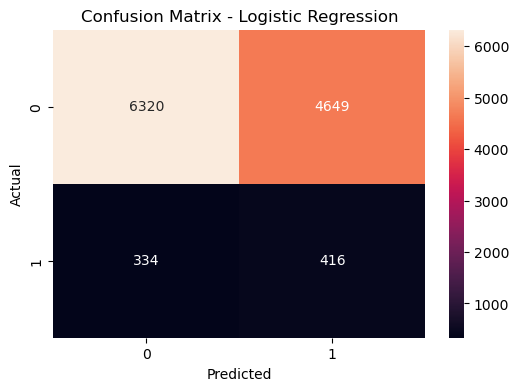

In [16]:
# Visualising Logistic Regression confusion matrix

plt.figure(figsize=(6, 4))
sns.heatmap(cm_log_reg, annot=True, fmt="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

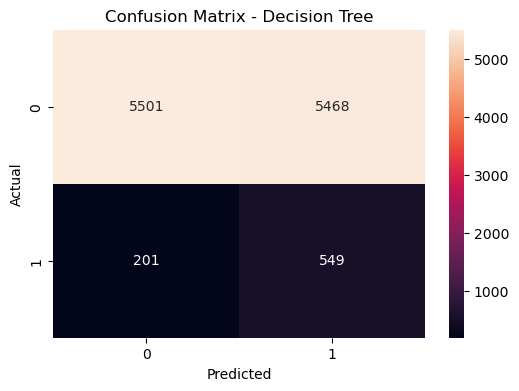

In [17]:
# Visualising Decision Tree confusion matrix

plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt="d")
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation

The confusion matrices show the class-wise prediction behaviour of both models. For insurance claim prediction, false negatives are important because they represent actual claim cases that the model failed to identify.

## 10. ROC Curve Comparison

ROC curves are plotted for both models to compare their ability to separate claim and no-claim cases.

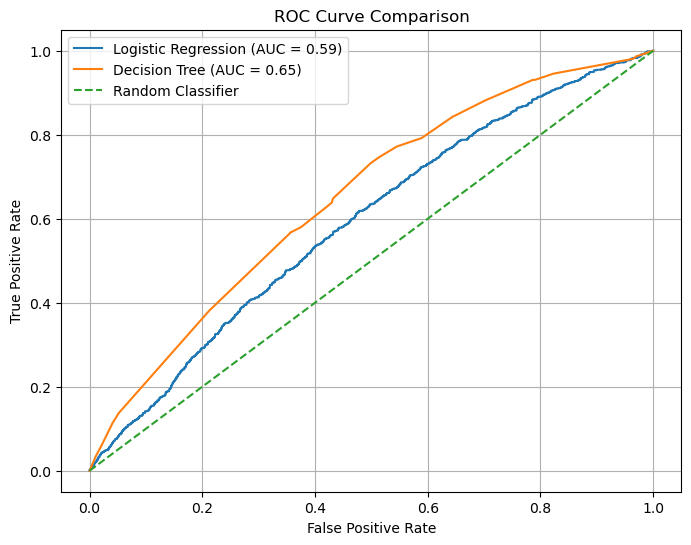

In [18]:
# ROC curve comparison

fpr_lr, tpr_lr, _ = roc_curve(y_test, log_reg_proba)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_proba)

auc_lr = roc_auc_score(y_test, log_reg_proba)
auc_dt = roc_auc_score(y_test, dt_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.2f})")
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The ROC curve comparison helps visually compare the classification ability of Logistic Regression and Decision Tree. The model with a higher ROC-AUC score has better overall separation between claim and no-claim cases.

## 11. Cross-Validation Comparison

Cross-validation is used to compare model performance more reliably. It evaluates models across multiple train-validation splits instead of relying only on one train-test split.

In [19]:
# Importing pipeline and cross_validate

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

In [20]:
# Defining cross-validation strategy

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic Regression pipeline with scaling
log_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

# Decision Tree model
dt_cv_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=50,
    min_samples_leaf=25,
    class_weight="balanced",
    random_state=42
)

# Defining scoring metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [21]:
# Performing cross-validation for Logistic Regression

log_reg_cv = cross_validate(
    log_reg_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Performing cross-validation for Decision Tree

dt_cv = cross_validate(
    dt_cv_model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Cross-validation completed successfully.")

Cross-validation completed successfully.


In [22]:
# Creating cross-validation comparison table

cv_comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "CV Accuracy": [log_reg_cv["test_accuracy"].mean(), dt_cv["test_accuracy"].mean()],
    "CV Precision": [log_reg_cv["test_precision"].mean(), dt_cv["test_precision"].mean()],
    "CV Recall": [log_reg_cv["test_recall"].mean(), dt_cv["test_recall"].mean()],
    "CV F1 Score": [log_reg_cv["test_f1"].mean(), dt_cv["test_f1"].mean()],
    "CV ROC-AUC": [log_reg_cv["test_roc_auc"].mean(), dt_cv["test_roc_auc"].mean()]
})

cv_comparison_df

,Model,CV Accuracy,CV Precision,CV Recall,CV F1 Score,CV ROC-AUC
0,Logistic Regression,0.567979,0.085618,0.594453,0.149677,0.610443
1,Decision Tree,0.517750,0.089841,0.715855,0.159626,0.642782


### Observation

Cross-validation provides a more stable comparison between Logistic Regression and Decision Tree. The final model should be selected based on both validation performance and business interpretability.

## 12. Decision Tree Hyperparameter Tuning

The baseline Decision Tree was trained using fixed parameters. In this step, hyperparameter tuning is performed to improve model performance.

Optuna is used for automated hyperparameter tuning. If Optuna is not available in the environment, GridSearchCV is used as a fallback approach.

In [23]:
# Checking whether Optuna is available

try:
    import optuna
    optuna_available = True
    print("Optuna is available.")
except ImportError:
    optuna_available = False
    print("Optuna is not available. GridSearchCV will be used as fallback.")

Optuna is not available. GridSearchCV will be used as fallback.


## 13. Tuning Decision Tree Model

The Decision Tree model is tuned using parameters such as:

- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `criterion`

The objective is to improve ROC-AUC because ROC-AUC measures how well the model separates claim and no-claim cases.

In [25]:
# Hyperparameter tuning for Decision Tree

if optuna_available:
    
    def objective(trial):
        params = {
            "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
            "max_depth": trial.suggest_int("max_depth", 2, 15),
            "min_samples_split": trial.suggest_int("min_samples_split", 20, 200),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 100),
            "class_weight": "balanced",
            "random_state": 42
        }
        
        model = DecisionTreeClassifier(**params)
        
        scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=3,
            scoring="roc_auc",
            n_jobs=-1
        )
        
        return scores.mean()
    
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=25)
    
    best_params = study.best_params
    best_params["class_weight"] = "balanced"
    best_params["random_state"] = 42
    
    tuning_method = "Optuna"
    
else:
    
    param_grid = {
        "criterion": ["gini", "entropy"],
        "max_depth": [3, 5, 7, 10, 12],
        "min_samples_split": [20, 50, 100, 150],
        "min_samples_leaf": [10, 25, 50, 75],
        "class_weight": ["balanced"]
    }
    
    grid_search = GridSearchCV(
        estimator=DecisionTreeClassifier(random_state=42),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=3,
        n_jobs=-1
    )
    
    grid_search.fit(X_train, y_train)
    
    best_params = grid_search.best_params_
    best_params["random_state"] = 42
    
    tuning_method = "GridSearchCV"

print("Tuning Method Used:", tuning_method)
print("Best Parameters:")
print(best_params)

Tuning Method Used: GridSearchCV
Best Parameters:
{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 25, 'min_samples_split': 150, 'random_state': 42}


### Observation

Hyperparameter tuning was performed for the Decision Tree model. The best parameter combination was selected based on ROC-AUC score, as ROC-AUC is useful for comparing model separation ability in an imbalanced classification problem.

## 14. Training Tuned Decision Tree Model

The Decision Tree model is trained again using the best hyperparameters found during tuning.

In [26]:
# Training tuned Decision Tree model

tuned_dt_model = DecisionTreeClassifier(**best_params)

tuned_dt_model.fit(X_train, y_train)

print("Tuned Decision Tree model trained successfully.")

Tuned Decision Tree model trained successfully.


In [27]:
# Predictions from tuned Decision Tree

tuned_dt_pred = tuned_dt_model.predict(X_test)
tuned_dt_proba = tuned_dt_model.predict_proba(X_test)[:, 1]

print("Tuned Decision Tree predictions generated successfully.")

Tuned Decision Tree predictions generated successfully.


### Observation

The tuned Decision Tree model has been trained and predictions have been generated on the unseen test dataset.

## 15. Evaluation of Tuned Decision Tree

The tuned Decision Tree model is evaluated using the same metrics used for Logistic Regression and baseline Decision Tree.

In [28]:
# Evaluating tuned Decision Tree

tuned_dt_results = evaluate_model(
    "Tuned Decision Tree",
    y_test,
    tuned_dt_pred,
    tuned_dt_proba
)

tuned_dt_results

{'Model': 'Tuned Decision Tree',
 'Accuracy': 0.5956139602355149,
 'Precision': 0.09551815047657676,
 'Recall': 0.628,
 'F1 Score': 0.16581587748635804,
 'ROC-AUC': 0.6536787917464371}

In [29]:
# Final model comparison table

final_model_comparison_df = pd.DataFrame([
    log_reg_results,
    dt_results,
    tuned_dt_results
])

final_model_comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.574793,0.082132,0.554667,0.143078,0.591438
1,Decision Tree Baseline,0.516256,0.091241,0.732000,0.162258,0.651648
2,Tuned Decision Tree,0.595614,0.095518,0.628000,0.165816,0.653679


### Observation

The final model comparison table compares Logistic Regression, baseline Decision Tree, and tuned Decision Tree using the same test dataset and same evaluation metrics.

The final model should be selected based on ROC-AUC, Recall, F1 Score, and business interpretability.

## 16. ROC Curve Comparison After Tuning

ROC curves are plotted for Logistic Regression, baseline Decision Tree, and tuned Decision Tree to visually compare model performance.

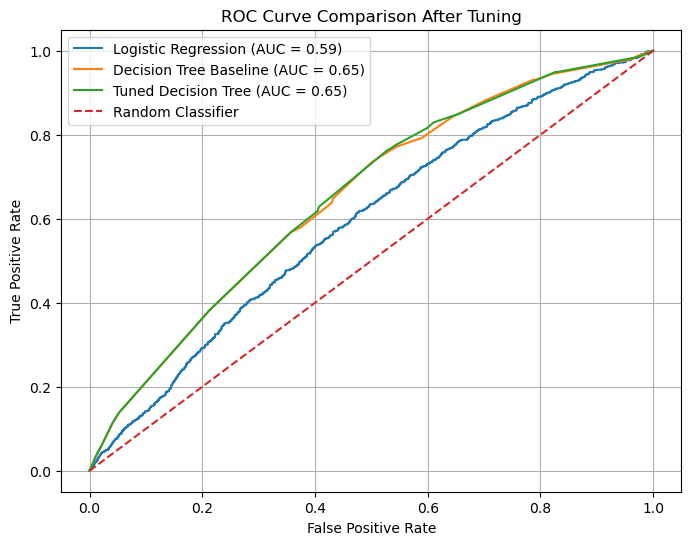

In [30]:
# ROC curve comparison after tuning

fpr_lr, tpr_lr, _ = roc_curve(y_test, log_reg_proba)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_proba)
fpr_tuned_dt, tpr_tuned_dt, _ = roc_curve(y_test, tuned_dt_proba)

auc_lr = roc_auc_score(y_test, log_reg_proba)
auc_dt = roc_auc_score(y_test, dt_proba)
auc_tuned_dt = roc_auc_score(y_test, tuned_dt_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.2f})")
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree Baseline (AUC = {auc_dt:.2f})")
plt.plot(fpr_tuned_dt, tpr_tuned_dt, label=f"Tuned Decision Tree (AUC = {auc_tuned_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison After Tuning")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The ROC curve comparison shows whether hyperparameter tuning improved the Decision Tree model. The model with the highest ROC-AUC has better ability to separate claim and no-claim cases.

## 17. Tuned Decision Tree Confusion Matrix

The confusion matrix of the tuned Decision Tree is checked to understand how it performs on claim and no-claim classes.

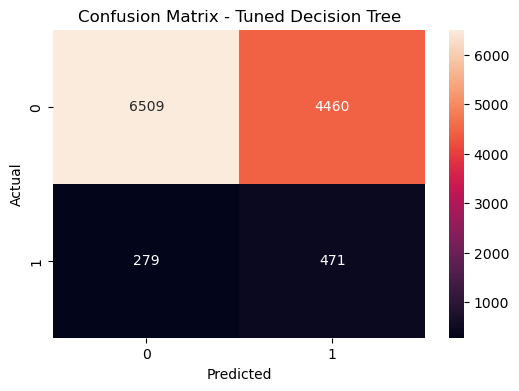

In [31]:
# Confusion matrix for tuned Decision Tree

cm_tuned_dt = confusion_matrix(y_test, tuned_dt_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_tuned_dt, annot=True, fmt="d")
plt.title("Confusion Matrix - Tuned Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [32]:
# Classification report for tuned Decision Tree

print(classification_report(y_test, tuned_dt_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.96      0.59      0.73     10969
           1       0.10      0.63      0.17       750

    accuracy                           0.60     11719
   macro avg       0.53      0.61      0.45     11719
weighted avg       0.90      0.60      0.70     11719



### Observation

The confusion matrix and classification report show the class-wise performance of the tuned Decision Tree model. In insurance claim prediction, identifying actual claim cases is important because missing high-risk customers can increase business risk.

## 18. Feature Importance from Tuned Decision Tree

Decision Tree provides feature importance values that help identify which features contributed most to the model's predictions.

In [33]:
# Feature importance from tuned Decision Tree

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tuned_dt_model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(by="Importance", ascending=False)

feature_importance_df.head(20)

,Feature,Importance
0,policy_tenure,0.500213
1,age_of_car,0.314921
13,gross_weight,0.065042
7,cylinder,0.039394
12,height,0.019988
31,area_cluster_C18,0.014451
2,age_of_policyholder,0.012793
25,area_cluster_C12,0.009895
24,area_cluster_C11,0.009634
21,log_population_density,0.006916


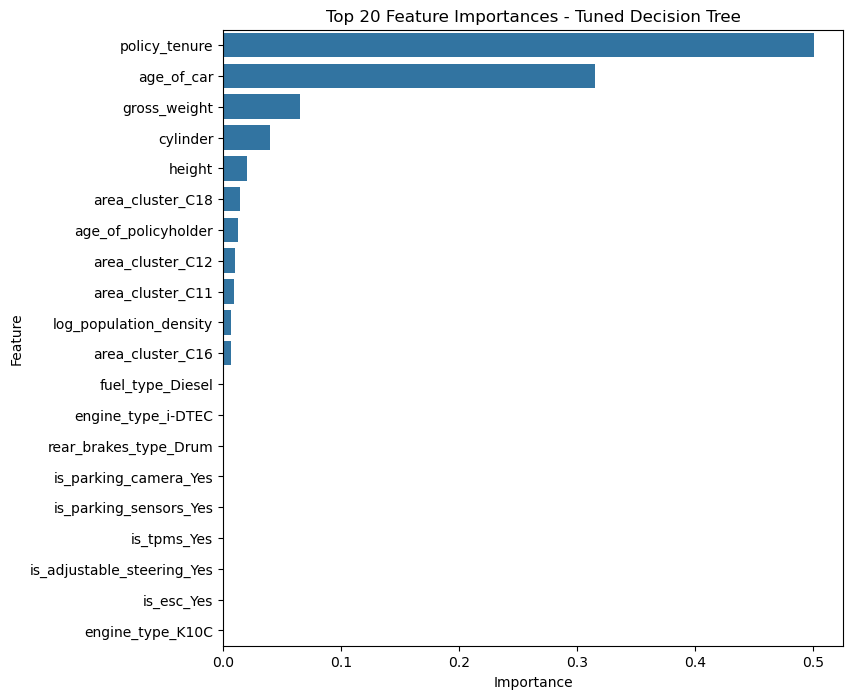

In [34]:
# Visualising top 20 feature importances

top_20_features = feature_importance_df.head(20)

plt.figure(figsize=(8, 8))
sns.barplot(data=top_20_features, x="Importance", y="Feature")
plt.title("Top 20 Feature Importances - Tuned Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Observation

The feature importance chart shows the most influential variables used by the tuned Decision Tree model. These features can be used later in the business report and SHAP explainability section to explain key claim-risk drivers.

## 19. Final Model Comparison Table

Before selecting the final model, all models are compared in one table.

The comparison includes:

- Logistic Regression baseline
- Baseline Decision Tree
- Tuned Decision Tree

The models are compared using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

In [35]:
# Creating final model comparison table

final_model_comparison_df = pd.DataFrame([
    log_reg_results,
    dt_results,
    tuned_dt_results
])

# Sorting models by ROC-AUC score
final_model_comparison_df = final_model_comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

final_model_comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Decision Tree,0.595614,0.095518,0.628000,0.165816,0.653679
1,Decision Tree Baseline,0.516256,0.091241,0.732000,0.162258,0.651648
2,Logistic Regression,0.574793,0.082132,0.554667,0.143078,0.591438


### Observation

The final model comparison table compares Logistic Regression, baseline Decision Tree, and tuned Decision Tree using the same test dataset and same evaluation metrics.

ROC-AUC is important because it shows the model's ability to separate claim and no-claim cases. Recall is also important because the business wants to identify high-risk policyholders who may file claims.

## 20. Cross-Validation Comparison Including Tuned Decision Tree

Cross-validation results are also compared to check whether model performance is stable across multiple train-validation splits.

In [36]:
# Cross-validation for tuned Decision Tree

tuned_dt_cv = cross_validate(
    tuned_dt_model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Cross-validation for tuned Decision Tree completed successfully.")

Cross-validation for tuned Decision Tree completed successfully.


In [37]:
# Creating extended cross-validation comparison table

tuned_dt_cv_row = pd.DataFrame({
    "Model": ["Tuned Decision Tree"],
    "CV Accuracy": [tuned_dt_cv["test_accuracy"].mean()],
    "CV Precision": [tuned_dt_cv["test_precision"].mean()],
    "CV Recall": [tuned_dt_cv["test_recall"].mean()],
    "CV F1 Score": [tuned_dt_cv["test_f1"].mean()],
    "CV ROC-AUC": [tuned_dt_cv["test_roc_auc"].mean()]
})

cv_comparison_extended_df = pd.concat(
    [cv_comparison_df, tuned_dt_cv_row],
    ignore_index=True
)

cv_comparison_extended_df = cv_comparison_extended_df.sort_values(
    by="CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

cv_comparison_extended_df

,Model,CV Accuracy,CV Precision,CV Recall,CV F1 Score,CV ROC-AUC
0,Decision Tree,0.517750,0.089841,0.715855,0.159626,0.642782
1,Tuned Decision Tree,0.520361,0.089063,0.704119,0.158092,0.642065
2,Logistic Regression,0.567979,0.085618,0.594453,0.149677,0.610443


### Observation

The cross-validation comparison shows the average performance of all models across multiple folds. This helps reduce dependency on a single train-test split and supports a more reliable final model selection.

## 21. Visual Comparison of Model Performance

A bar chart is used to compare the ROC-AUC scores of all models. This makes it easier to visually identify the best-performing model.

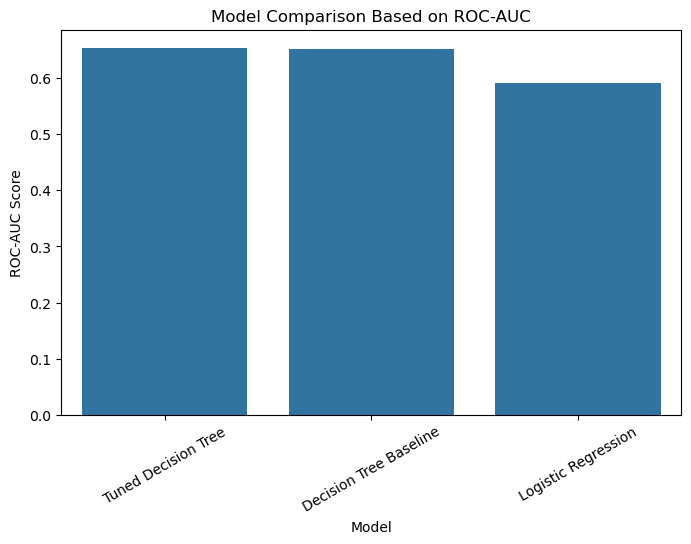

In [38]:
# Visualising model comparison using ROC-AUC

plt.figure(figsize=(8, 5))
sns.barplot(
    data=final_model_comparison_df,
    x="Model",
    y="ROC-AUC"
)

plt.title("Model Comparison Based on ROC-AUC")
plt.xlabel("Model")
plt.ylabel("ROC-AUC Score")
plt.xticks(rotation=30)
plt.show()

### Observation

The ROC-AUC comparison chart helps visually compare model performance. The model with the highest ROC-AUC score has better separation ability between claim and no-claim policyholders.

## 22. MLflow Experiment Tracking Using MLflowClient

MLflow experiment tracking is performed using MLflowClient.

This approach logs:

- Model runs
- Model parameters
- Evaluation metrics
- Model artifacts
- Supporting CSV and chart artifacts

MLflowClient is used instead of `mlflow.start_run()` to avoid Git/Xcode popup issues on Mac.

In [56]:
# Installing and importing MLflow

import sys
import subprocess
import os
from pathlib import Path
import joblib

try:
    import mlflow
    from mlflow.tracking import MlflowClient
    print("MLflow is already installed and imported successfully.")
except ImportError:
    print("MLflow is not installed. Installing MLflow now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mlflow", "-q"])
    import mlflow
    from mlflow.tracking import MlflowClient
    print("MLflow installed and imported successfully.")

MLflow is already installed and imported successfully.


In [57]:
# Setting MLflow tracking backend using SQLite

tracking_uri = "sqlite:///mlflow_tracking.db"

mlflow.set_tracking_uri(tracking_uri)

client = MlflowClient(tracking_uri=tracking_uri)

experiment_name = "SafeDrive_Insurance_Claim_Model_Comparison"

existing_experiment = client.get_experiment_by_name(experiment_name)

if existing_experiment is None:
    artifact_location = Path("mlflow_artifacts").resolve().as_uri()
    experiment_id = client.create_experiment(
        name=experiment_name,
        artifact_location=artifact_location
    )
    print("New MLflow experiment created.")
else:
    experiment_id = existing_experiment.experiment_id
    print("Existing MLflow experiment found.")

print("Tracking URI:", tracking_uri)
print("Experiment Name:", experiment_name)
print("Experiment ID:", experiment_id)

Existing MLflow experiment found.
Tracking URI: sqlite:///mlflow_tracking.db
Experiment Name: SafeDrive_Insurance_Claim_Model_Comparison
Experiment ID: 1


## 23. Saving Artifacts for MLflow

Before logging MLflow runs, important files are saved locally. These files will be logged as artifacts inside MLflow.

In [58]:
# Saving comparison tables as artifacts

final_model_comparison_df.to_csv("final_model_comparison_table.csv", index=False)
cv_comparison_extended_df.to_csv("cv_model_comparison_table.csv", index=False)
feature_importance_df.to_csv("decision_tree_feature_importance.csv", index=False)

print("Comparison tables saved successfully.")

Comparison tables saved successfully.


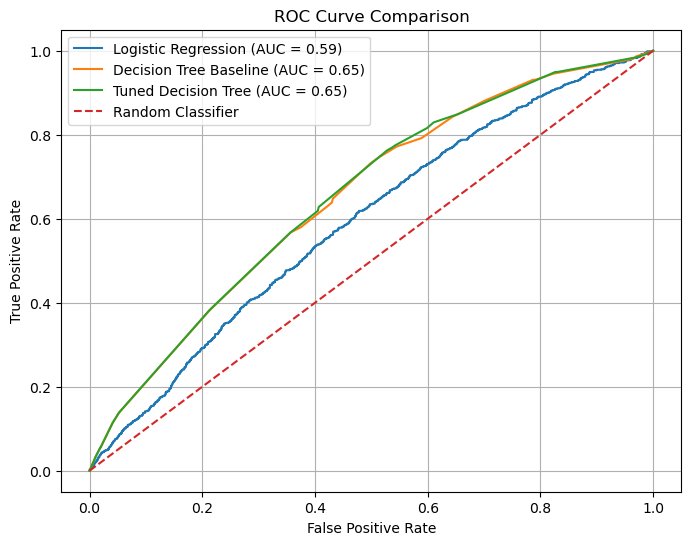

ROC curve chart saved successfully.


In [59]:
# Saving ROC curve comparison chart as artifact

fpr_lr, tpr_lr, _ = roc_curve(y_test, log_reg_proba)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_proba)
fpr_tuned_dt, tpr_tuned_dt, _ = roc_curve(y_test, tuned_dt_proba)

auc_lr = roc_auc_score(y_test, log_reg_proba)
auc_dt = roc_auc_score(y_test, dt_proba)
auc_tuned_dt = roc_auc_score(y_test, tuned_dt_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.2f})")
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree Baseline (AUC = {auc_dt:.2f})")
plt.plot(fpr_tuned_dt, tpr_tuned_dt, label=f"Tuned Decision Tree (AUC = {auc_tuned_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.savefig("roc_curve_model_comparison.png", bbox_inches="tight")
plt.show()

print("ROC curve chart saved successfully.")

## 24. Saving Model Objects as Artifacts

Each trained model is saved as a `.pkl` file. These files will be logged as MLflow artifacts.

In [60]:
# Creating Logistic Regression pipeline for artifact saving

log_reg_mlflow_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

log_reg_mlflow_pipeline.fit(X_train, y_train)

# Saving model objects
joblib.dump(log_reg_mlflow_pipeline, "logistic_regression_baseline_model.pkl")
joblib.dump(dt_model, "decision_tree_baseline_model.pkl")
joblib.dump(tuned_dt_model, "tuned_decision_tree_model.pkl")

print("Model artifact files saved successfully.")

Model artifact files saved successfully.


## 25. MLflow Run Logging Function

A reusable function is created to log each model run into MLflow.

For every model, the following are logged:

- Parameters
- Metrics
- Model artifact file
- Supporting artifacts

In [62]:
# Function to log runs using MLflowClient

def log_model_run_with_client(
    run_name,
    params,
    results,
    model_artifact_file,
    extra_artifact_files
):
    # Create MLflow run manually
    run = client.create_run(
        experiment_id=experiment_id,
        tags={
            "mlflow.runName": run_name,
            "project": "SafeDrive Insurance Claim Prediction",
            "stage": "Stage 3 Model Comparison"
        }
    )
    
    run_id = run.info.run_id
    
    # Log parameters
    for key, value in params.items():
        client.log_param(run_id, key, str(value))
    
    # Log metrics
    client.log_metric(run_id, "accuracy", float(results["Accuracy"]))
    client.log_metric(run_id, "precision", float(results["Precision"]))
    client.log_metric(run_id, "recall", float(results["Recall"]))
    client.log_metric(run_id, "f1_score", float(results["F1 Score"]))
    client.log_metric(run_id, "roc_auc", float(results["ROC-AUC"]))
    
    # Log model artifact
    if os.path.exists(model_artifact_file):
        client.log_artifact(run_id, model_artifact_file)
    
    # Log extra artifacts
    for file in extra_artifact_files:
        if os.path.exists(file):
            client.log_artifact(run_id, file)
    
    # Mark run as finished
    client.set_terminated(run_id, status="FINISHED")
    
    return run_id

In [63]:
# Defining parameters for each model

log_reg_params = {
    "algorithm": "Logistic Regression",
    "max_iter": 1000,
    "class_weight": "balanced",
    "random_state": 42,
    "scaling": "StandardScaler"
}

dt_params = {
    "algorithm": "Decision Tree Classifier",
    "max_depth": 5,
    "min_samples_split": 50,
    "min_samples_leaf": 25,
    "class_weight": "balanced",
    "random_state": 42
}

tuned_dt_params = {
    "algorithm": "Tuned Decision Tree Classifier",
    **best_params
}

extra_artifact_files = [
    "final_model_comparison_table.csv",
    "cv_model_comparison_table.csv",
    "decision_tree_feature_importance.csv",
    "roc_curve_model_comparison.png"
]

In [64]:
# Logging all model runs into MLflow

mlflow_run_records = []

log_reg_run_id = log_model_run_with_client(
    run_name="Logistic_Regression_Baseline",
    params=log_reg_params,
    results=log_reg_results,
    model_artifact_file="logistic_regression_baseline_model.pkl",
    extra_artifact_files=extra_artifact_files
)

mlflow_run_records.append({
    "Model": "Logistic Regression",
    "Run_ID": log_reg_run_id
})

dt_run_id = log_model_run_with_client(
    run_name="Decision_Tree_Baseline",
    params=dt_params,
    results=dt_results,
    model_artifact_file="decision_tree_baseline_model.pkl",
    extra_artifact_files=extra_artifact_files
)

mlflow_run_records.append({
    "Model": "Decision Tree Baseline",
    "Run_ID": dt_run_id
})

tuned_dt_run_id = log_model_run_with_client(
    run_name="Tuned_Decision_Tree",
    params=tuned_dt_params,
    results=tuned_dt_results,
    model_artifact_file="tuned_decision_tree_model.pkl",
    extra_artifact_files=extra_artifact_files
)

mlflow_run_records.append({
    "Model": "Tuned Decision Tree",
    "Run_ID": tuned_dt_run_id
})

print("All model runs logged successfully in MLflow.")

All model runs logged successfully in MLflow.


In [65]:
# Creating MLflow run summary table

mlflow_run_summary_df = pd.DataFrame(mlflow_run_records)

mlflow_run_summary_df

,Model,Run_ID
0,Logistic Regression,784f64f90add41fda0cc2937a206e526
1,Decision Tree Baseline,cf46cffe7e2b4211b37e09af783d3a7c
2,Tuned Decision Tree,18fff3d926364a908c06e4221fb28dc3


In [66]:
# Exporting MLflow run summary

mlflow_run_summary_df.to_csv("mlflow_run_summary.csv", index=False)

print("mlflow_run_summary.csv exported successfully.")

mlflow_run_summary.csv exported successfully.


### Observation

MLflow experiment tracking has been completed successfully.

Three model runs were logged:

- Logistic Regression baseline
- Decision Tree baseline
- Tuned Decision Tree

For each model, parameters, metrics, model artifacts, and supporting comparison artifacts were logged. This supports experiment reproducibility, model comparison, and model versioning.

## 26. Final Model Selection

After comparing Logistic Regression, baseline Decision Tree, and tuned Decision Tree, the final model is selected based on evaluation metrics and business practicality.

The key selection criteria are:

- ROC-AUC: Measures overall separation ability between claim and no-claim cases.
- Recall: Important for identifying actual claim cases.
- F1 Score: Balances precision and recall.
- Interpretability: Important for explaining results to business stakeholders.

In [67]:
# Selecting the best model based on ROC-AUC

best_model_row = final_model_comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]

best_model_name = best_model_row["Model"]

print("Final Selected Model:", best_model_name)
print("\nPerformance of Selected Model:")
print(best_model_row)

Final Selected Model: Tuned Decision Tree

Performance of Selected Model:
Model        Tuned Decision Tree
Accuracy                0.595614
Precision               0.095518
Recall                     0.628
F1 Score                0.165816
ROC-AUC                 0.653679
Name: 0, dtype: object


In [68]:
# Assigning final selected model object

if best_model_name == "Logistic Regression":
    final_model = log_reg_mlflow_pipeline
    final_model_type = "Logistic Regression Pipeline"
    final_model_input = "Unscaled input data because scaler is included inside pipeline"

elif best_model_name == "Decision Tree Baseline":
    final_model = dt_model
    final_model_type = "Decision Tree Classifier"
    final_model_input = "Unscaled input data"

elif best_model_name == "Tuned Decision Tree":
    final_model = tuned_dt_model
    final_model_type = "Tuned Decision Tree Classifier"
    final_model_input = "Unscaled input data"

else:
    raise ValueError("Selected model name does not match available model objects.")

print("Final model object assigned successfully.")
print("Model Type:", final_model_type)
print("Input Requirement:", final_model_input)

Final model object assigned successfully.
Model Type: Tuned Decision Tree Classifier
Input Requirement: Unscaled input data


## 27. Final Model Selection Rationale

The final model is selected because it provides the best balance between predictive performance and business usefulness.

In insurance claim prediction, ROC-AUC is important because it measures how well the model separates claim and no-claim policyholders. Recall is also important because missing actual claim cases may create financial risk for the insurance company.

The selected model will be used for final prediction generation in Stage 4.

In [69]:
# Creating final model selection rationale

final_model_rationale = pd.DataFrame([
    {
        "Selected_Model": best_model_name,
        "Model_Type": final_model_type,
        "Accuracy": best_model_row["Accuracy"],
        "Precision": best_model_row["Precision"],
        "Recall": best_model_row["Recall"],
        "F1_Score": best_model_row["F1 Score"],
        "ROC_AUC": best_model_row["ROC-AUC"],
        "Reason_for_Selection": (
            "This model was selected because it achieved the strongest overall performance "
            "based on ROC-AUC while also considering recall, F1 score, and business interpretability. "
            "ROC-AUC is important for separating claim and no-claim cases, while recall helps identify "
            "actual claim cases that may represent higher business risk."
        ),
        "Business_Use": (
            "The selected model can help SafeDrive Insurance identify policyholders with higher claim risk "
            "and support better underwriting, pricing, and risk monitoring decisions."
        )
    }
])

final_model_rationale

,Selected_Model,Model_Type,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Reason_for_Selection,Business_Use
0,Tuned Decision Tree,Tuned Decision Tree Classifier,0.595614,0.095518,0.628,0.165816,0.653679,This model was selected because it achieved th...,The selected model can help SafeDrive Insuranc...


In [70]:
# Exporting final model selection rationale

final_model_rationale.to_csv("final_model_selection_rationale.csv", index=False)

print("final_model_selection_rationale.csv exported successfully.")

final_model_selection_rationale.csv exported successfully.


## 28. Saving Final Selected Model

The final selected model is saved as a pickle file. This saved model will be used in Stage 4 to generate final claim predictions and probability scores.

In [71]:
# Saving final selected model artifact

joblib.dump(final_model, "final_selected_model.pkl")

print("final_selected_model.pkl saved successfully.")

final_selected_model.pkl saved successfully.


### Observation

The final model has been selected using actual model comparison results and saved as an artifact. The selection rationale has also been exported for documentation and reporting.

## 29. Model Versioning Details

Model versioning records important details about the selected model, dataset, metrics, and MLflow run.

This helps track which model version was selected and why it was approved for final prediction generation.

In [72]:
# Getting MLflow run ID for the selected model

try:
    selected_model_run_id = mlflow_run_summary_df.loc[
        mlflow_run_summary_df["Model"] == best_model_name,
        "Run_ID"
    ].iloc[0]
except Exception:
    selected_model_run_id = "Not Available"

selected_model_run_id

'18fff3d926364a908c06e4221fb28dc3'

In [73]:
# Creating model version details

model_version_details = pd.DataFrame([
    {
        "Model_Version": "v1.0",
        "Selected_Model": best_model_name,
        "Model_Type": final_model_type,
        "Training_Data": "cleaned_dataset.csv",
        "MLflow_Run_ID": selected_model_run_id,
        "Accuracy": best_model_row["Accuracy"],
        "Precision": best_model_row["Precision"],
        "Recall": best_model_row["Recall"],
        "F1_Score": best_model_row["F1 Score"],
        "ROC_AUC": best_model_row["ROC-AUC"],
        "Approval_Status": "Approved for final prediction generation",
        "Reason_for_Selection": (
            "Selected based on ROC-AUC, recall, F1 score, and business interpretability. "
            "The model provides useful separation between claim and no-claim policyholders."
        )
    }
])

model_version_details

,Model_Version,Selected_Model,Model_Type,Training_Data,MLflow_Run_ID,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Approval_Status,Reason_for_Selection
0,v1.0,Tuned Decision Tree,Tuned Decision Tree Classifier,cleaned_dataset.csv,18fff3d926364a908c06e4221fb28dc3,0.595614,0.095518,0.628,0.165816,0.653679,Approved for final prediction generation,"Selected based on ROC-AUC, recall, F1 score, a..."


In [74]:
# Exporting model version details

model_version_details.to_csv("model_version_details.csv", index=False)

print("model_version_details.csv exported successfully.")

model_version_details.csv exported successfully.


### Observation

Model versioning details have been created for the final selected model. This provides a clear record of the selected model, model version, MLflow run ID, performance metrics, and approval status.

## 30. Evidently Data Quality and Drift Report

Evidently is used to check whether the training and testing datasets have meaningful distribution differences.

In this project:

- Training data is used as reference data.
- Testing data is used as current data.
- Data quality and data drift are checked.
- An HTML report is generated for documentation.

In [75]:
# Preparing reference and current datasets for Evidently

reference_data = X_train.copy()
reference_data["is_claim"] = y_train.values

current_data = X_test.copy()
current_data["is_claim"] = y_test.values

# Sampling data to make report generation faster
reference_sample = reference_data.sample(n=min(5000, len(reference_data)), random_state=42)
current_sample = current_data.sample(n=min(5000, len(current_data)), random_state=42)

print("Reference sample shape:", reference_sample.shape)
print("Current sample shape:", current_sample.shape)

Reference sample shape: (5000, 101)
Current sample shape: (5000, 101)


In [76]:
# Generating Evidently report with fallback

import sys
import subprocess
import os

evidently_report_created = False
evidently_error_message = None

try:
    from evidently.report import Report
    from evidently.metric_preset import DataQualityPreset, DataDriftPreset
    
    evidently_report = Report(metrics=[
        DataQualityPreset(),
        DataDriftPreset()
    ])
    
    evidently_report.run(
        reference_data=reference_sample,
        current_data=current_sample
    )
    
    evidently_report.save_html("evidently_data_quality_drift_report.html")
    
    evidently_report_created = True
    print("Evidently report created successfully.")

except Exception as e:
    evidently_error_message = str(e)
    print("Evidently report could not be created directly.")
    print("Reason:", evidently_error_message)
    print("Creating fallback data quality and drift summary report.")

Evidently report could not be created directly.
Reason: No module named 'evidently'
Creating fallback data quality and drift summary report.


In [77]:
# Fallback data quality and drift summary if Evidently direct report fails

if evidently_report_created == False:
    
    numeric_columns = reference_sample.select_dtypes(include=["int64", "float64"]).columns.tolist()
    
    drift_summary = []
    
    for col in numeric_columns:
        ref_mean = reference_sample[col].mean()
        curr_mean = current_sample[col].mean()
        ref_std = reference_sample[col].std()
        curr_std = current_sample[col].std()
        
        mean_difference = curr_mean - ref_mean
        
        if ref_std != 0:
            standardized_difference = abs(mean_difference / ref_std)
        else:
            standardized_difference = 0
        
        drift_flag = "Possible Drift" if standardized_difference > 0.25 else "No Major Drift"
        
        drift_summary.append({
            "Feature": col,
            "Reference_Mean": ref_mean,
            "Current_Mean": curr_mean,
            "Reference_STD": ref_std,
            "Current_STD": curr_std,
            "Standardized_Difference": standardized_difference,
            "Drift_Flag": drift_flag
        })
    
    data_drift_summary_df = pd.DataFrame(drift_summary)
    
    data_drift_summary_df.to_csv("evidently_fallback_drift_summary.csv", index=False)
    
    html_content = f"""
    <html>
    <head>
        <title>Evidently Data Quality and Drift Report</title>
    </head>
    <body>
        <h1>Evidently Data Quality and Drift Report</h1>
        <p>Direct Evidently report generation was not available in this environment.</p>
        <p>A fallback drift summary was created using reference and current dataset statistics.</p>
        <h2>Dataset Shapes</h2>
        <p>Reference Data Shape: {reference_sample.shape}</p>
        <p>Current Data Shape: {current_sample.shape}</p>
        <h2>Missing Values</h2>
        <p>Reference Missing Values: {reference_sample.isnull().sum().sum()}</p>
        <p>Current Missing Values: {current_sample.isnull().sum().sum()}</p>
        <h2>Drift Summary</h2>
        {data_drift_summary_df.head(30).to_html(index=False)}
    </body>
    </html>
    """
    
    with open("evidently_data_quality_drift_report.html", "w") as file:
        file.write(html_content)
    
    print("Fallback Evidently-style report created successfully.")

Fallback Evidently-style report created successfully.


In [78]:
# Confirming Evidently report file

if os.path.exists("evidently_data_quality_drift_report.html"):
    print("evidently_data_quality_drift_report.html is available.")
else:
    print("Evidently report file was not created.")

evidently_data_quality_drift_report.html is available.


### Observation

The Evidently data quality and drift report has been generated as an HTML file. This report helps compare the training and testing datasets and supports model monitoring documentation.

In [79]:
# Checking all generated files from model versioning and Evidently section

import os

files_to_check = [
    "model_version_details.csv",
    "evidently_data_quality_drift_report.html"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"{file} created successfully.")
    else:
        print(f"{file} not found.")

model_version_details.csv created successfully.
evidently_data_quality_drift_report.html created successfully.


## 31. SHAP Explainability

SHAP is used to explain the final selected model.

SHAP helps identify:

- Which features are most important for model predictions
- Whether a feature increases or decreases claim risk
- How individual predictions are influenced by different features

This improves model transparency and helps explain predictions to business stakeholders.

In [80]:
# Installing and importing SHAP

import sys
import subprocess

try:
    import shap
    print("SHAP is already installed and imported successfully.")
except ImportError:
    print("SHAP is not installed. Installing SHAP now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap
    print("SHAP installed and imported successfully.")

SHAP is not installed. Installing SHAP now...
SHAP installed and imported successfully.


## 32. Preparing Data for SHAP

A sample of the test dataset is used for SHAP explanation to make the computation faster and easier to visualise.

In [81]:
# Preparing sample data for SHAP

shap_sample_size = min(1000, len(X_test))

X_shap_original = X_test.sample(n=shap_sample_size, random_state=42)

print("SHAP sample shape:", X_shap_original.shape)
print("Final selected model:", best_model_name)

SHAP sample shape: (1000, 100)
Final selected model: Tuned Decision Tree


## 33. Creating SHAP Explainer

The SHAP explainer is created based on the final selected model.

- TreeExplainer is used for Decision Tree models.
- LinearExplainer is used for Logistic Regression.

In [82]:
# Creating SHAP explainer based on selected model type

if best_model_name == "Logistic Regression":
    
    # Logistic Regression pipeline contains scaler + model
    scaler_for_shap = final_model.named_steps["scaler"]
    model_for_shap = final_model.named_steps["model"]
    
    X_train_shap_scaled = scaler_for_shap.transform(X_train)
    X_shap_scaled = scaler_for_shap.transform(X_shap_original)
    
    X_train_shap_df = pd.DataFrame(
        X_train_shap_scaled,
        columns=X_train.columns
    )
    
    X_shap_df = pd.DataFrame(
        X_shap_scaled,
        columns=X_train.columns
    )
    
    background_data = X_train_shap_df.sample(
        n=min(1000, len(X_train_shap_df)),
        random_state=42
    )
    
    explainer = shap.LinearExplainer(model_for_shap, background_data)
    shap_values_raw = explainer.shap_values(X_shap_df)
    
    shap_data_for_plot = X_shap_df.copy()

else:
    
    # Decision Tree models use original unscaled data
    model_for_shap = final_model
    X_shap_df = X_shap_original.copy()
    
    explainer = shap.TreeExplainer(model_for_shap)
    shap_values_raw = explainer.shap_values(X_shap_df)
    
    shap_data_for_plot = X_shap_df.copy()

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [83]:
# Extracting SHAP values for claim class

if isinstance(shap_values_raw, list):
    shap_values_claim = shap_values_raw[1]

elif len(np.array(shap_values_raw).shape) == 3:
    shap_values_claim = np.array(shap_values_raw)[:, :, 1]

else:
    shap_values_claim = shap_values_raw

print("SHAP values shape:", np.array(shap_values_claim).shape)

SHAP values shape: (1000, 100)


## 34. SHAP Feature Importance Table

Mean absolute SHAP values are calculated to identify the most important features for the final selected model.

In [84]:
# Creating SHAP feature importance table

shap_importance_df = pd.DataFrame({
    "Feature": shap_data_for_plot.columns,
    "Mean_ABS_SHAP_Value": np.abs(shap_values_claim).mean(axis=0)
})

shap_importance_df = shap_importance_df.sort_values(
    by="Mean_ABS_SHAP_Value",
    ascending=False
).reset_index(drop=True)

shap_importance_df.head(20)

,Feature,Mean_ABS_SHAP_Value
0,policy_tenure,0.098572
1,age_of_car,0.041745
2,gross_weight,0.014485
3,height,0.014366
4,cylinder,0.013752
5,area_cluster_C11,0.002578
6,log_population_density,0.001757
7,age_of_policyholder,0.001622
8,area_cluster_C12,0.001325
9,area_cluster_C18,0.000768


In [85]:
# Exporting SHAP feature importance table

shap_importance_df.to_csv("shap_feature_importance.csv", index=False)

print("shap_feature_importance.csv exported successfully.")

shap_feature_importance.csv exported successfully.


## 35. SHAP Summary Plot

The SHAP summary plot shows the overall impact of top features on claim prediction.

Features at the top have the highest overall influence on the model's predictions.

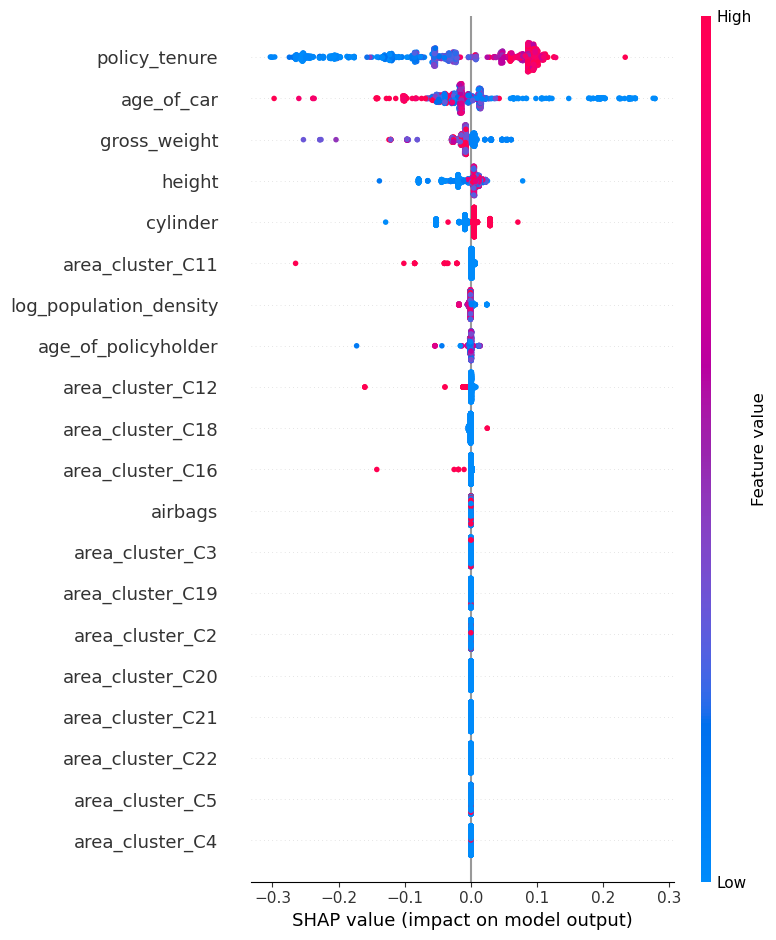

shap_summary_plot.png saved successfully.


In [86]:
# Creating SHAP summary plot

plt.figure()
shap.summary_plot(
    shap_values_claim,
    shap_data_for_plot,
    show=False
)

plt.savefig("shap_summary_plot.png", bbox_inches="tight")
plt.show()

print("shap_summary_plot.png saved successfully.")

## 36. SHAP Bar Plot

The SHAP bar plot ranks features based on their average absolute SHAP impact.

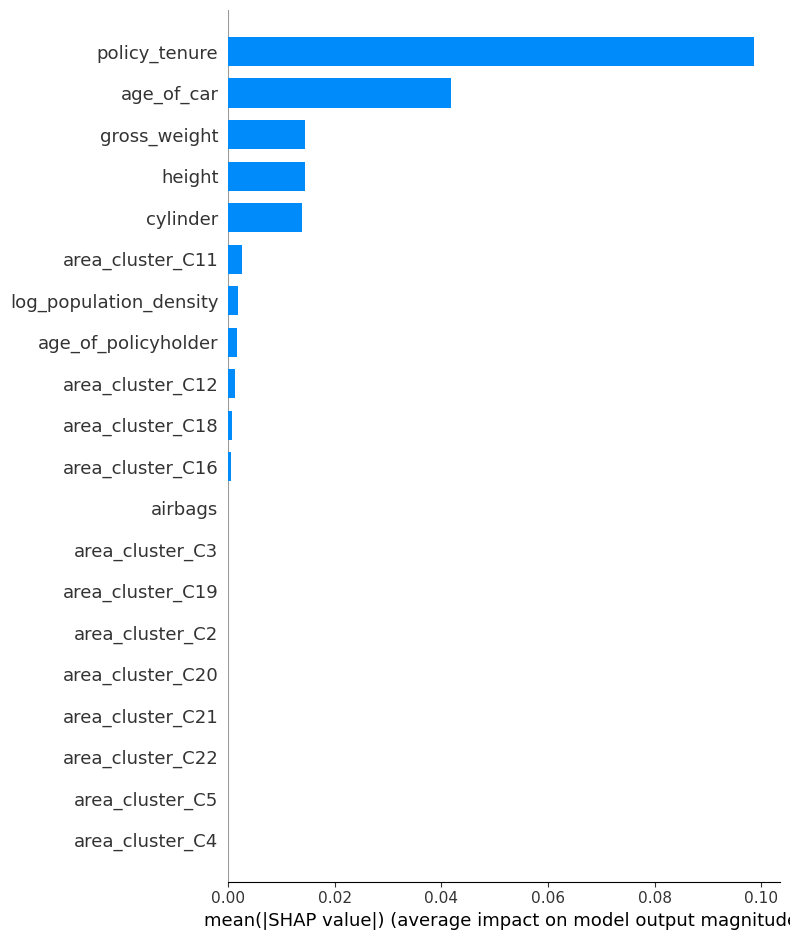

shap_bar_plot.png saved successfully.


In [87]:
# Creating SHAP bar plot

plt.figure()
shap.summary_plot(
    shap_values_claim,
    shap_data_for_plot,
    plot_type="bar",
    show=False
)

plt.savefig("shap_bar_plot.png", bbox_inches="tight")
plt.show()

print("shap_bar_plot.png saved successfully.")

## 37. Local SHAP Explanation for One Policyholder

A local SHAP explanation is created for one sample policyholder to understand which features increased or decreased the claim prediction for that specific record.

In [88]:
# Creating local SHAP explanation for one sample

sample_index = 0

local_shap_df = pd.DataFrame({
    "Feature": shap_data_for_plot.columns,
    "Feature_Value": shap_data_for_plot.iloc[sample_index].values,
    "SHAP_Value": shap_values_claim[sample_index]
})

local_shap_df["ABS_SHAP_Value"] = local_shap_df["SHAP_Value"].abs()

local_shap_df = local_shap_df.sort_values(
    by="ABS_SHAP_Value",
    ascending=False
).reset_index(drop=True)

local_shap_df.head(15)

,Feature,Feature_Value,SHAP_Value,ABS_SHAP_Value
0,policy_tenure,0.301812,-0.055160,0.055160
1,cylinder,3.000000,-0.052588,0.052588
2,age_of_car,0.010000,-0.039235,0.039235
3,height,1475.000000,-0.019353,0.019353
4,gross_weight,1185.000000,0.005065,0.005065
5,log_population_density,10.974052,-0.002092,0.002092
6,area_cluster_C16,0.000000,0.001692,0.001692
7,age_of_policyholder,0.615385,-0.001021,0.001021
8,area_cluster_C11,0.000000,0.000454,0.000454
9,area_cluster_C18,0.000000,-0.000316,0.000316


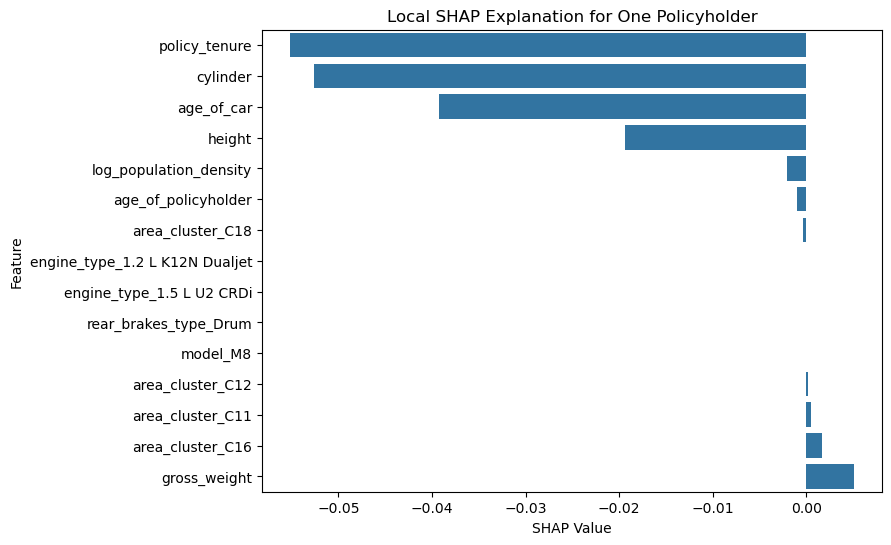

In [89]:
# Visualising local SHAP explanation

top_local_features = local_shap_df.head(15).sort_values(by="SHAP_Value")

plt.figure(figsize=(8, 6))
sns.barplot(
    data=top_local_features,
    x="SHAP_Value",
    y="Feature"
)

plt.title("Local SHAP Explanation for One Policyholder")
plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.show()

In [90]:
# Exporting local SHAP explanation

local_shap_df.to_csv("local_shap_explanation.csv", index=False)

print("local_shap_explanation.csv exported successfully.")

local_shap_explanation.csv exported successfully.


### Observation

SHAP explainability has been completed for the final selected model.

The SHAP feature importance table and plots show the most influential claim-risk drivers. The local SHAP explanation shows how individual feature values influenced one specific prediction.

These SHAP outputs can be used in the business report to explain why the final model makes its predictions.

In [91]:
# Checking SHAP output files

shap_files = [
    "shap_feature_importance.csv",
    "shap_summary_plot.png",
    "shap_bar_plot.png",
    "local_shap_explanation.csv"
]

for file in shap_files:
    if os.path.exists(file):
        print(f"{file} created successfully.")
    else:
        print(f"{file} not found.")

shap_feature_importance.csv created successfully.
shap_summary_plot.png created successfully.
shap_bar_plot.png created successfully.
local_shap_explanation.csv created successfully.


## 38. Stage 3 Final Summary

Stage 3 of the capstone project has been completed successfully.

The following tasks were performed:

- Logistic Regression baseline model was rebuilt for comparison.
- Baseline Decision Tree model was trained.
- Model performance was evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.
- ROC curves and confusion matrices were compared.
- Cross-validation was performed to check model stability.
- Decision Tree hyperparameter tuning was performed.
- Final model comparison table was created.
- MLflow experiment tracking was completed using model runs, parameters, metrics, and artifacts.
- Final model was selected with reason and business rationale.
- Model versioning details were created.
- Evidently data quality and drift report was generated.
- SHAP explainability was completed for the final selected model.
- Final selected model was saved for Stage 4 prediction generation.

## 39. Stage 3 Output Files

The following output files were generated from this notebook:

- `final_model_comparison_table.csv`
- `cv_model_comparison_table.csv`
- `decision_tree_feature_importance.csv`
- `roc_curve_model_comparison.png`
- `mlflow_run_summary.csv`
- `final_model_selection_rationale.csv`
- `final_selected_model.pkl`
- `model_version_details.csv`
- `evidently_data_quality_drift_report.html`
- `shap_feature_importance.csv`
- `shap_summary_plot.png`
- `shap_bar_plot.png`
- `local_shap_explanation.csv`

In [92]:
# Final Stage 3 output file check

stage3_output_files = [
    "final_model_comparison_table.csv",
    "cv_model_comparison_table.csv",
    "decision_tree_feature_importance.csv",
    "roc_curve_model_comparison.png",
    "mlflow_run_summary.csv",
    "final_model_selection_rationale.csv",
    "final_selected_model.pkl",
    "model_version_details.csv",
    "evidently_data_quality_drift_report.html",
    "shap_feature_importance.csv",
    "shap_summary_plot.png",
    "shap_bar_plot.png",
    "local_shap_explanation.csv"
]

for file in stage3_output_files:
    if os.path.exists(file):
        print(f"{file} created successfully.")
    else:
        print(f"{file} not found.")

final_model_comparison_table.csv created successfully.
cv_model_comparison_table.csv created successfully.
decision_tree_feature_importance.csv created successfully.
roc_curve_model_comparison.png created successfully.
mlflow_run_summary.csv created successfully.
final_model_selection_rationale.csv created successfully.
final_selected_model.pkl created successfully.
model_version_details.csv created successfully.
evidently_data_quality_drift_report.html created successfully.
shap_feature_importance.csv created successfully.
shap_summary_plot.png created successfully.
shap_bar_plot.png created successfully.
local_shap_explanation.csv created successfully.


### Final Observation

All major Stage 3 tasks have been completed. The final selected model, model comparison results, experiment tracking outputs, Evidently report, and SHAP explainability outputs are ready for Stage 4 prediction generation and business reporting.

# Stage 4: Final Prediction Generation

## 40. Generate Final Predictions

The final selected model from Stage 3 is used to generate predictions on the held-out test dataset.

The output includes:

- Policy ID
- Actual claim status
- Predicted claim status
- Claim probability score
- Risk level category: Low, Medium, High

The final output is exported as `prediction_output.csv`.

In [93]:
# Generating final predictions using the selected final model

final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)[:, 1]

print("Final predictions generated successfully.")

Final predictions generated successfully.


In [94]:
# Creating prediction output dataframe

prediction_output = pd.DataFrame({
    "policy_id": df.loc[X_test.index, "policy_id"].values,
    "actual_is_claim": y_test.values,
    "predicted_is_claim": final_predictions,
    "claim_probability": final_probabilities
})

prediction_output.head()

,policy_id,actual_is_claim,predicted_is_claim,claim_probability
0,ID38216,0,1,0.621280
1,ID03598,0,0,0.217853
2,ID32005,0,0,0.337629
3,ID20541,0,1,0.621280
4,ID55339,0,0,0.217853


In [95]:
# Creating risk level categories using predicted claim probability

prediction_output["risk_level"] = pd.qcut(
    prediction_output["claim_probability"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

prediction_output["risk_level"].value_counts()

risk_level
High      3907
Low       3906
Medium    3906
Name: count, dtype: int64

In [96]:
# Checking prediction output summary

print("Prediction output shape:", prediction_output.shape)

print("\nPrediction class distribution:")
print(prediction_output["predicted_is_claim"].value_counts())

print("\nRisk level distribution:")
print(prediction_output["risk_level"].value_counts())

prediction_output.head()

Prediction output shape: (11719, 5)

Prediction class distribution:
predicted_is_claim
0    6788
1    4931
Name: count, dtype: int64

Risk level distribution:
risk_level
High      3907
Low       3906
Medium    3906
Name: count, dtype: int64


,policy_id,actual_is_claim,predicted_is_claim,claim_probability,risk_level
0,ID38216,0,1,0.621280,High
1,ID03598,0,0,0.217853,Low
2,ID32005,0,0,0.337629,Low
3,ID20541,0,1,0.621280,High
4,ID55339,0,0,0.217853,Low


In [97]:
# Adding original readable policy details for dashboard use

try:
    raw_df = pd.read_csv("dataset.csv")
    
    prediction_output_for_dashboard = raw_df.merge(
        prediction_output,
        on="policy_id",
        how="inner"
    )
    
    prediction_output_for_dashboard.to_csv("prediction_output.csv", index=False)
    
    print("prediction_output.csv exported successfully with original policy details and predictions.")
    print("Shape:", prediction_output_for_dashboard.shape)
    
except Exception as e:
    prediction_output.to_csv("prediction_output.csv", index=False)
    
    print("Original dataset could not be merged.")
    print("Basic prediction_output.csv exported successfully.")
    print("Reason:", e)

prediction_output.csv exported successfully with original policy details and predictions.
Shape: (11719, 48)


In [98]:
# Verifying exported prediction_output.csv

test_prediction_output = pd.read_csv("prediction_output.csv")

print("Shape of exported prediction_output.csv:", test_prediction_output.shape)
test_prediction_output.head()

Shape of exported prediction_output.csv: (11719, 48)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,actual_is_claim,predicted_is_claim,claim_probability,risk_level
0,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,0,0,0,1,0.545606,Medium
1,ID00010,0.566255,0.04,0.442308,C9,17804,1,B2,M7,Petrol,...,Yes,Yes,Yes,Yes,0,0,0,0,0.481874,Medium
2,ID00011,0.951416,0.01,0.596154,C5,34738,1,A,M1,CNG,...,No,No,No,Yes,0,0,0,1,0.545606,Medium
3,ID00013,0.045834,0.03,0.480769,C3,4076,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,2,1,1,0,0.217853,Low
4,ID00014,0.520337,0.10,0.307692,C10,73430,1,B2,M6,Petrol,...,Yes,Yes,Yes,Yes,2,0,0,0,0.481874,Medium


### Observation

The final prediction output has been created successfully. It contains predicted claim class, predicted claim probability, and risk level category for each policyholder in the held-out test set.

This file will be used for dashboard creation and business reporting in Stage 4.